## Student Performance Indicator


#### Life cycle of Machine learning Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### 1) Problem statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.


### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

### 2.1 Import Data and Required Packages
####  Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [28]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


#### Import the CSV Data as Pandas DataFrame

In [29]:
df = pd.read_csv('data/stud.csv')

### Show top 5 records

In [30]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Shape

In [31]:
df.shape

(1000, 8)

## 2.2 Dataset Information


- gender : sex of students  -> (Male/female)
- race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
- parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
- lunch : having lunch before test (standard or free/reduced) 
- test preparation course : complete or not complete before test
- math score
- reading score
- writing score

### 3. Data Checks to perform

- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

## Check missing values

In [32]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

### there are no missing values


## check duplicates

In [33]:
df.duplicated().sum()

np.int64(0)

### there are no duplicate values


## check data types

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


## check number of unique values for each column 

In [35]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

## check stat of data set

In [36]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


#### Insight
- From above description of numerical data, all means are very close to each other - between 66 and 68.05;
- All standard deviations are also close - between 14.6 and 15.19;
- While there is a minimum score  0 for math, for writing minimum is much higher = 10 and for reading myet higher = 17

### Exploring Data

In [37]:
print("Categories in 'gender' variable:     ",end=" " )
print(df['gender'].unique())

print("Categories in 'race_ethnicity' variable:  ",end=" ")
print(df['race_ethnicity'].unique())

print("Categories in'parental level of education' variable:",end=" " )
print(df['parental_level_of_education'].unique())

print("Categories in 'lunch' variable:     ",end=" " )
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable:     ",end=" " )
print(df['test_preparation_course'].unique())

Categories in 'gender' variable:      <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race_ethnicity' variable:   <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in'parental level of education' variable: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable:      <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable:      <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [38]:

categorical_features = df.select_dtypes(include=['object', 'string']).columns.tolist()
numeric_features = df.select_dtypes(exclude=['object', 'string']).columns.tolist()

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['math_score', 'reading_score', 'writing_score']

We have 5 categorical features : ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


### Adding columns for "Total Score" and "Average"

In [39]:
df['total score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total score']/3
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [40]:
reading_full = df[df['reading_score'] == 100]['average'].count()
writing_full = df[df['writing_score'] == 100]['average'].count()
math_full = df[df['math_score'] == 100]['average'].count()

print(f'Number of students with full marks in Maths: {math_full}')
print(f'Number of students with full marks in Writing: {writing_full}')
print(f'Number of students with full marks in Reading: {reading_full}')

Number of students with full marks in Maths: 7
Number of students with full marks in Writing: 14
Number of students with full marks in Reading: 17


In [41]:
reading_less_20 = df[df['reading_score'] <= 20]['average'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average'].count()
math_less_20 = df[df['math_score'] <= 20]['average'].count()

print(f'Number of students with less than 20 marks in Maths: {math_less_20}')
print(f'Number of students with less than 20 marks in Writing: {writing_less_20}')
print(f'Number of students with less than 20 marks in Reading: {reading_less_20}')

Number of students with less than 20 marks in Maths: 4
Number of students with less than 20 marks in Writing: 3
Number of students with less than 20 marks in Reading: 1


#####  Insights
 - From above values we get students have performed the worst in Maths 
 - Best performance is in reading section

###  Exploring Data ( Visualization )
####  Visualize average score distribution to make some conclusion. 
- Histogram
- Kernel Distribution Function (KDE)

#### Histogram & KDE

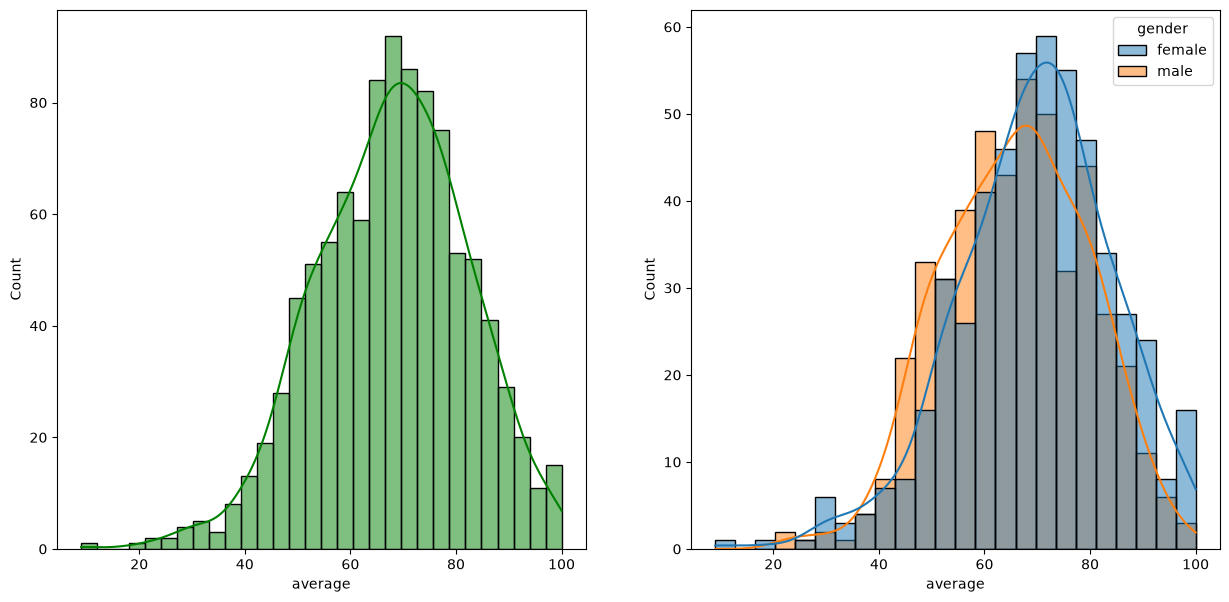

In [42]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df, x='average', bins=30, kde=True, color='g')
plt.subplot(122)
sns.histplot(data=df, x='average', kde=True, hue='gender')
plt.show()

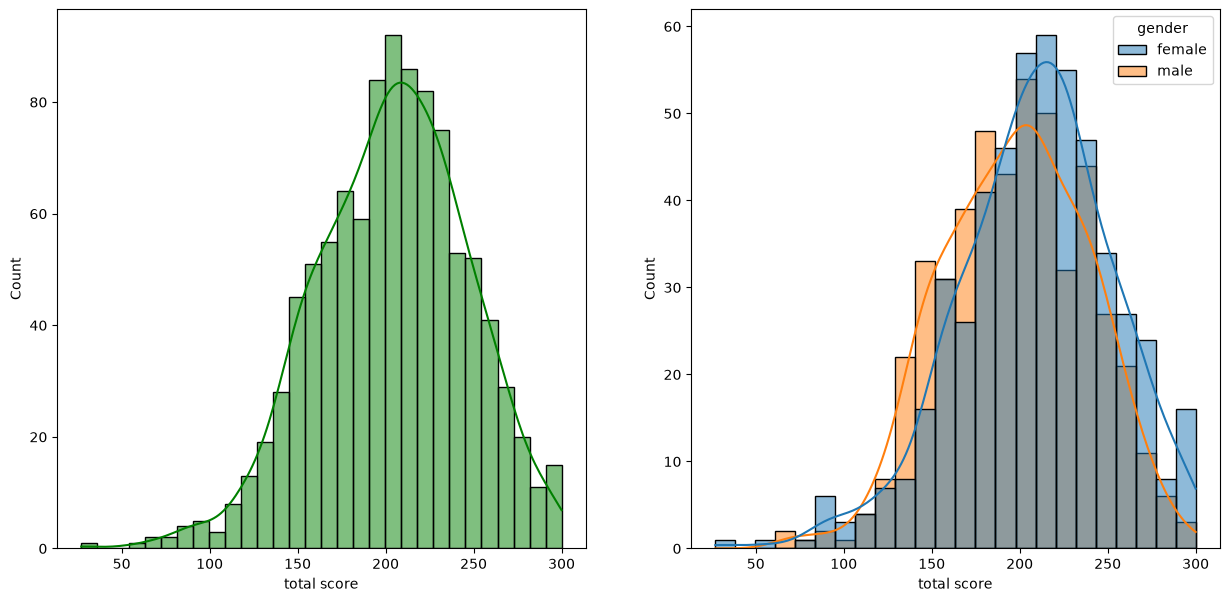

In [43]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df, x='total score', bins=30, kde=True, color='g')
plt.subplot(122)
sns.histplot(data=df, x='total score', kde=True, hue='gender')
plt.show()

#####  Insights
- Female students tend to perform well then male students.

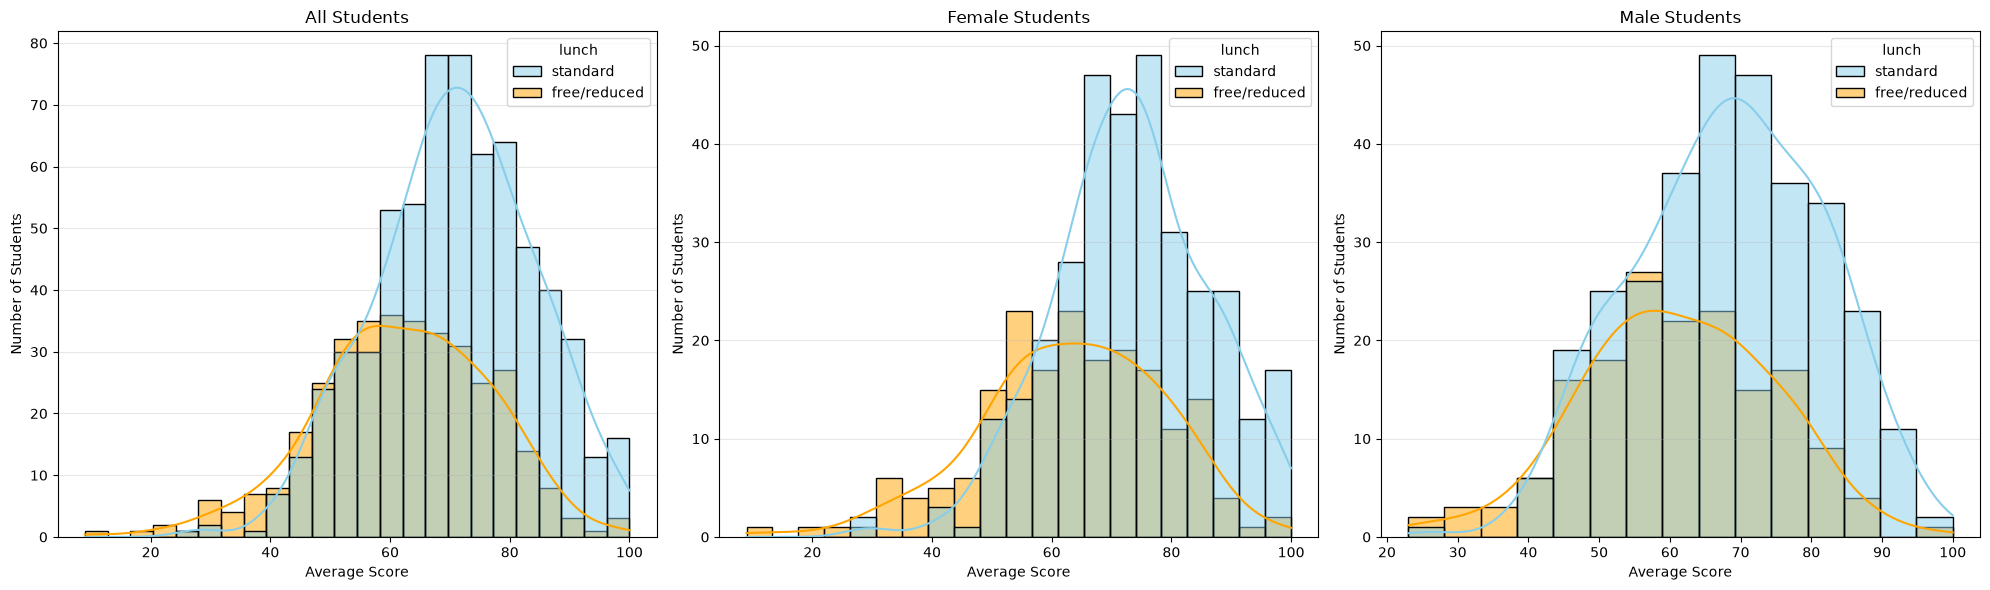

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Define consistent colors
colors = {
    'standard': 'skyblue',
    'free/reduced': 'orange'
}

hue_order = ['standard', 'free/reduced']

# All Students
sns.histplot(data=df, x='average', kde=True, hue='lunch',
             hue_order=hue_order, palette=colors, ax=axes[0])
axes[0].set_title('All Students')

# Female Students
sns.histplot(data=df[df['gender'] == 'female'],
             x='average', kde=True, hue='lunch',
             hue_order=hue_order, palette=colors, ax=axes[1])
axes[1].set_title('Female Students')

# Male Students
sns.histplot(data=df[df['gender'] == 'male'],
             x='average', kde=True, hue='lunch',
             hue_order=hue_order, palette=colors, ax=axes[2])
axes[2].set_title('Male Students')

for ax in axes:
    ax.set_xlabel('Average Score')
    ax.set_ylabel('Number of Students')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

#####  Insights
- Standard lunch helps perform well in exams.
- Standard lunch helps perform well in exams be it a male or a female.

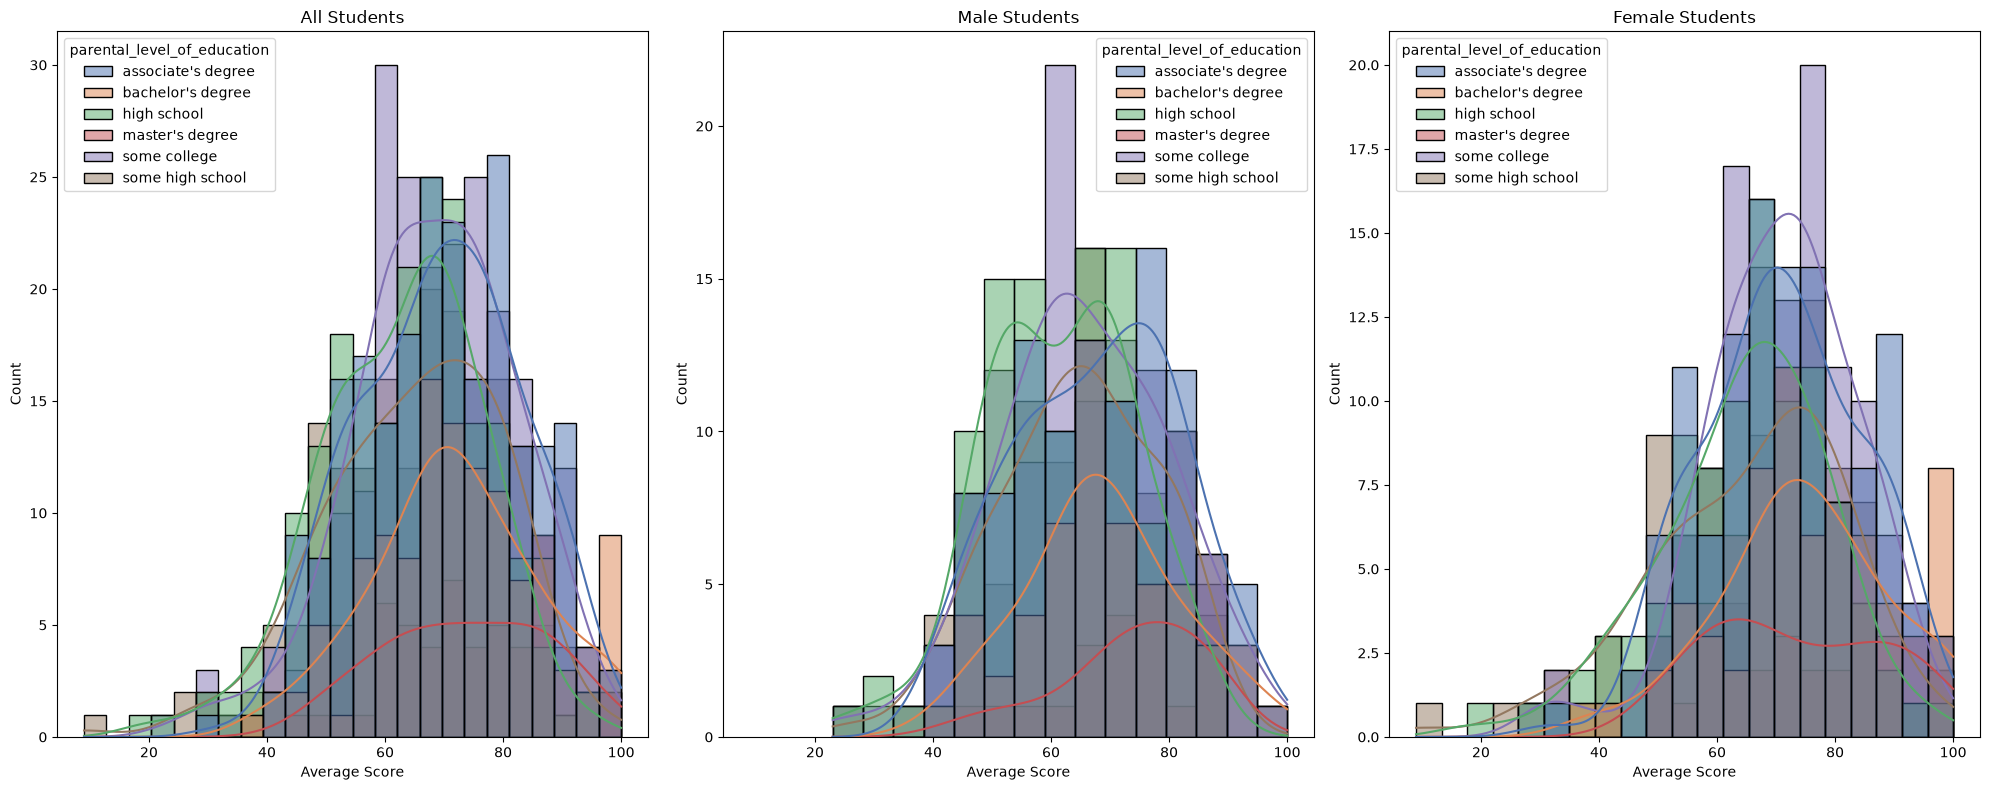

In [68]:

education_levels = sorted(
    df["parental_level_of_education"].dropna().unique()
)
colors = sns.color_palette("deep", n_colors=len(education_levels))
palette = dict(zip(education_levels, colors))

fig, axes = plt.subplots(1, 3, figsize=(20, 8), sharex=True)

groups = [
    ("All Students", df),
    ("Male Students", df[df["gender"] == "male"]),
    ("Female Students", df[df["gender"] == "female"]),
]

for ax, (title, data) in zip(axes, groups):
    sns.histplot(
        data=data,
        x="average",
        hue="parental_level_of_education",
        hue_order=education_levels,
        palette=palette,
        kde=True,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Average Score")

axes[0].set_ylabel("Count")
fig.tight_layout()
plt.show()

#####  Insights
- In general parent's education don't help student perform well in exam.
- 2nd plot shows that parent's whose education is of associate's degree or master's degree their male child tend to perform well in exam
- 3rd plot we can see there is no effect of parent's education on female students.

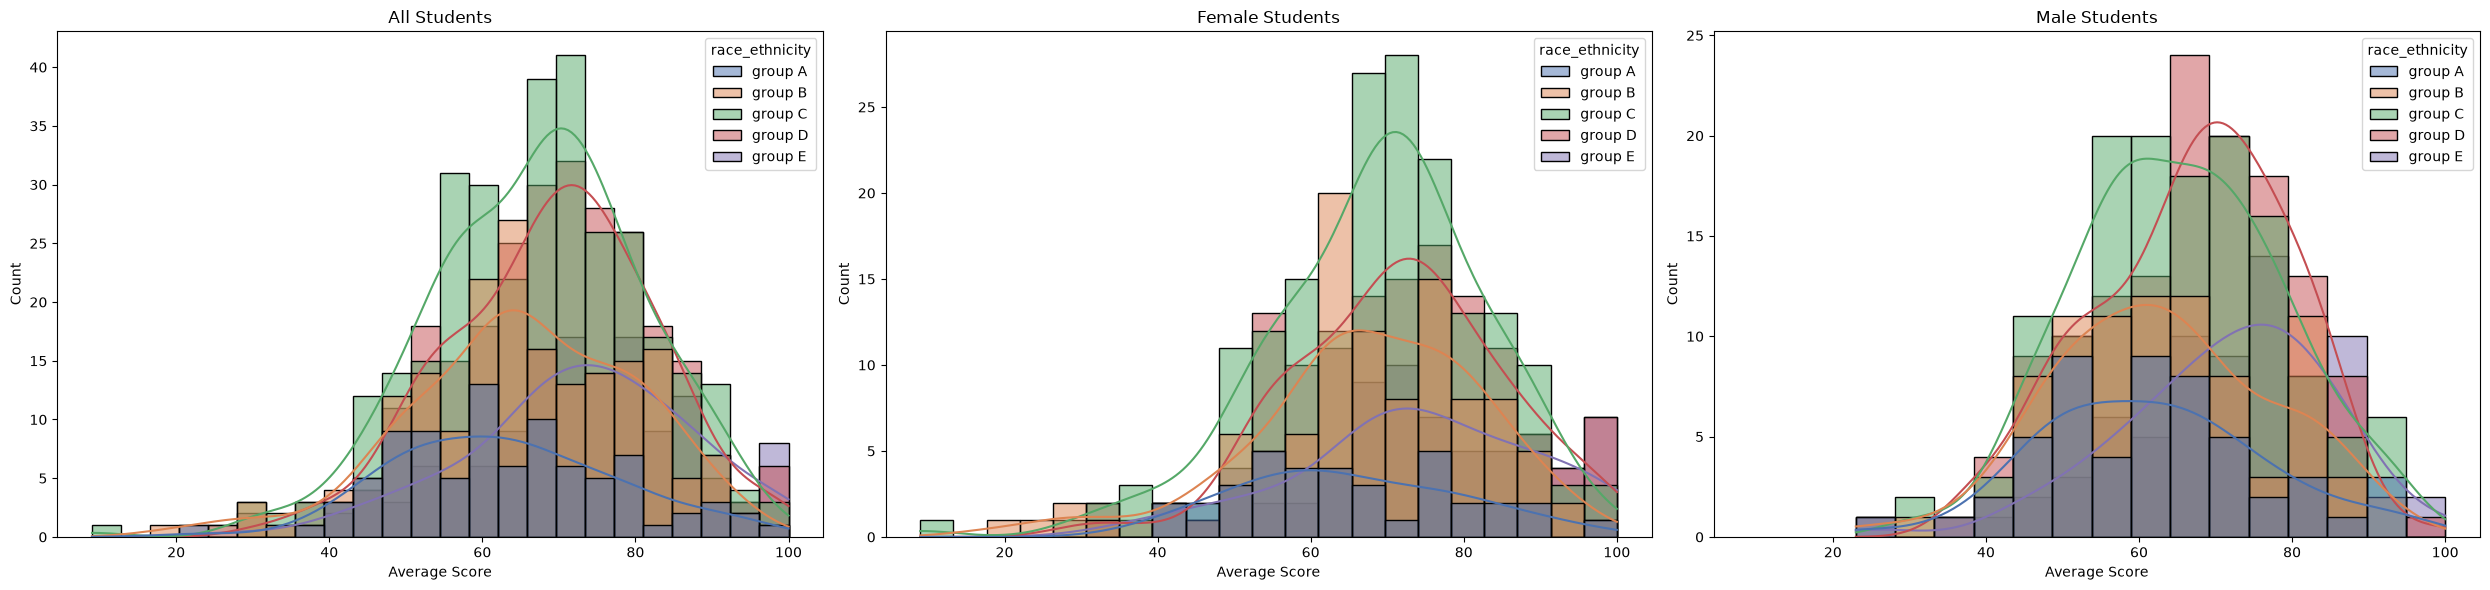

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

race_groups = sorted(df["race_ethnicity"].dropna().unique())
colors = sns.color_palette("deep", n_colors=len(race_groups))
palette = dict(zip(race_groups, colors))

fig, axes = plt.subplots(1, 3, figsize=(25, 6), sharex=True)

groups = [
    ("All Students", df),
    ("Female Students", df[df["gender"] == "female"]),
    ("Male Students", df[df["gender"] == "male"]),
]

for ax, (title, data) in zip(axes, groups):
    sns.histplot(
        data=data,
        x="average",
        hue="race_ethnicity",
        hue_order=race_groups,
        palette=palette,
        kde=True,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Average Score")

axes[0].set_ylabel("Count")
fig.tight_layout()
plt.show()

#####  Insights
- Students of group A and group B tends to perform poorly in exam.
- Students of group A and group B tends to perform poorly in exam irrespective of whether they are male or female


In [77]:
df.columns.to_list()

['gender',
 'race_ethnicity',
 'parental_level_of_education',
 'lunch',
 'test_preparation_course',
 'math_score',
 'reading_score',
 'writing_score',
 'total score',
 'average']

####  Maximumum score of students in all three subjects

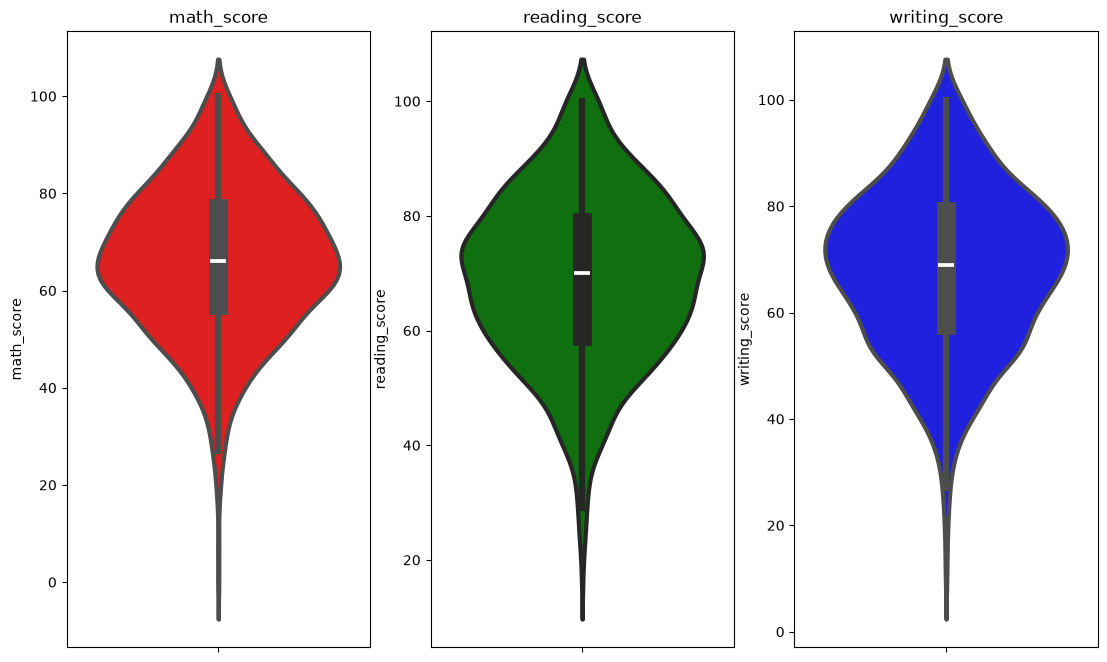

In [79]:

plt.figure(figsize=(18,8))
plt.subplot(1, 4, 1)
plt.title( 'math_score')
sns.violinplot(y='math_score',data=df,color='red',linewidth=3)
plt.subplot(1, 4, 2)
plt.title('reading_score')
sns.violinplot(y='reading_score',data=df,color='green',linewidth=3)
plt.subplot(1, 4, 3)
plt.title('writing_score')
sns.violinplot(y='writing_score',data=df,color='blue',linewidth=3)
plt.show()

#### Insights
- From the above three plots its clearly visible that most of the students score in between 60-80 in Maths whereas in reading and writing most of them score from 50-80

####  Multivariate analysis using pieplot

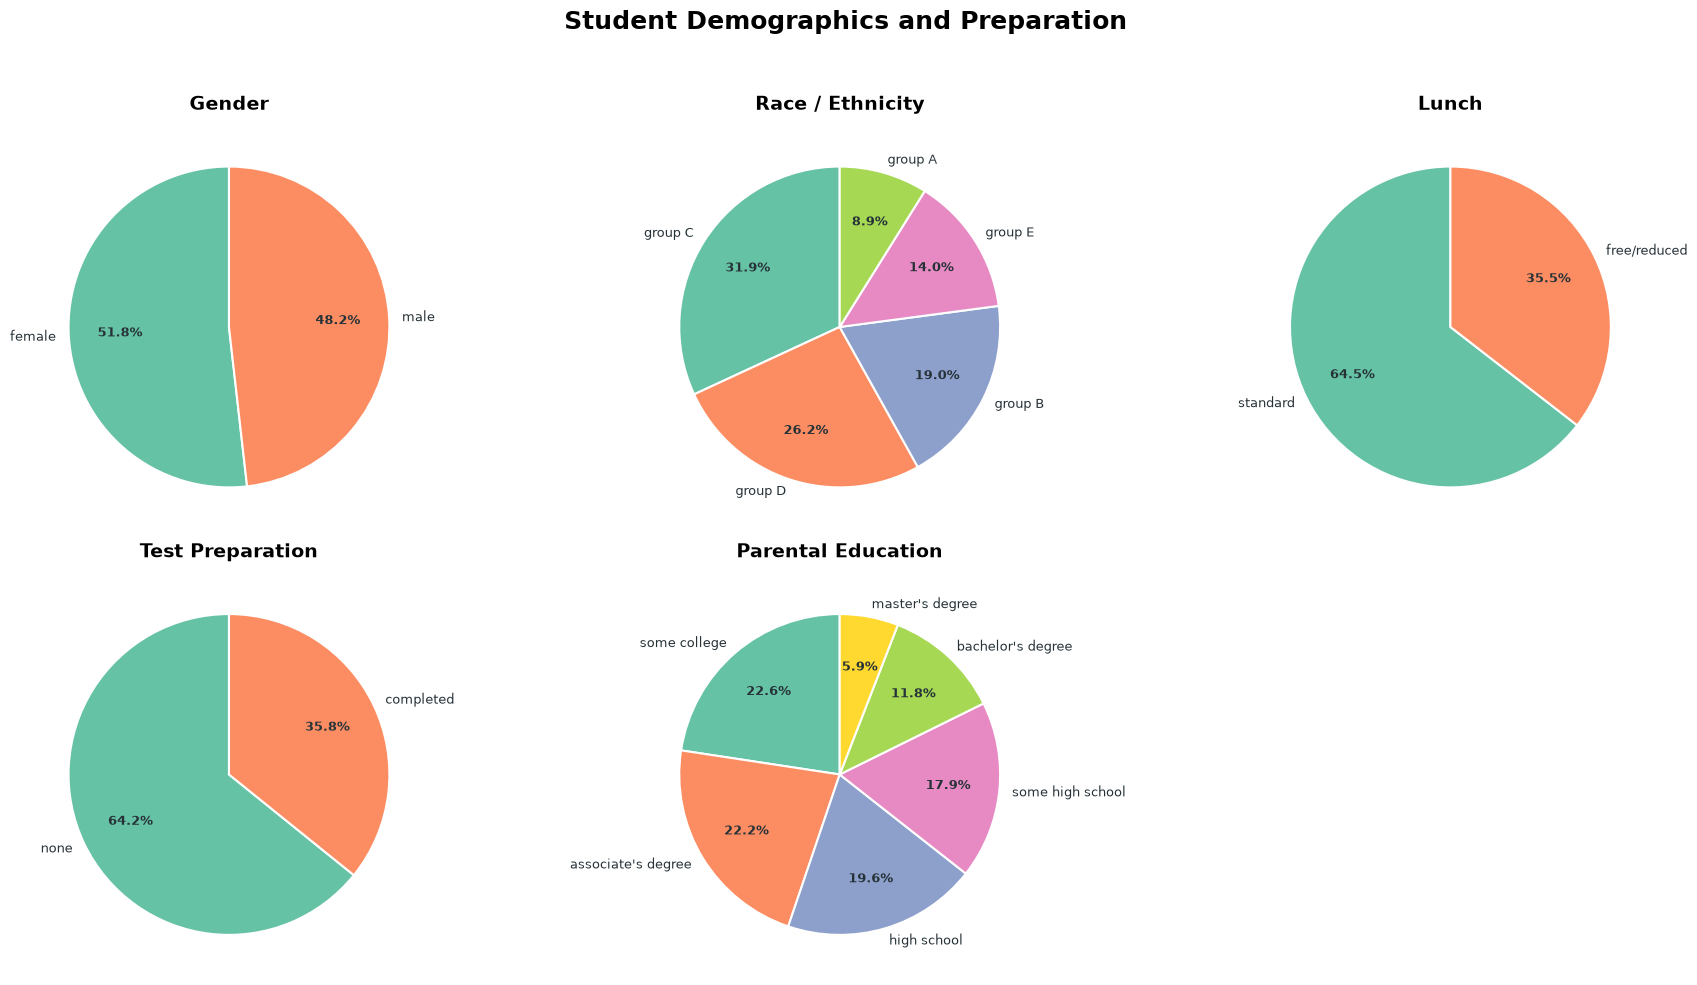

In [83]:


columns = [
    ("gender", "Gender"),
    ("race_ethnicity", "Race / Ethnicity"),
    ("lunch", "Lunch"),
    ("test_preparation_course", "Test Preparation"),
    ("parental_level_of_education", "Parental Education"),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (column, title) in zip(axes, columns):
    counts = df[column].value_counts(dropna=True)
    colors = sns.color_palette("Set2", n_colors=len(counts))

    _, label_texts, percent_texts = ax.pie(
        counts.values,
        labels=counts.index.astype(str),  # Labels stay matched to their counts
        colors=colors,
        autopct="%1.1f%%",
        startangle=90,
        labeldistance=1.08,
        pctdistance=0.68,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5},
        textprops={"fontsize": 9, "color": "#263238"},
    )

    for text in percent_texts:
        text.set_fontweight("bold")

    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    ax.set_aspect("equal")

# Remove the unused sixth subplot
fig.delaxes(axes[-1])

fig.suptitle("Student Demographics and Preparation", fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

#####  Insights
- Number of Male and Female students is almost equal
- Number students are greatest in Group C
- Number of students who have standard lunch are greater
- Number of students who have not enrolled in any test preparation course is greater
- Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

####  Feature Wise Visualization
####  GENDER COLUMN


#### UNIVARIATE ANALYSIS ( How is distribution of Gender ? )

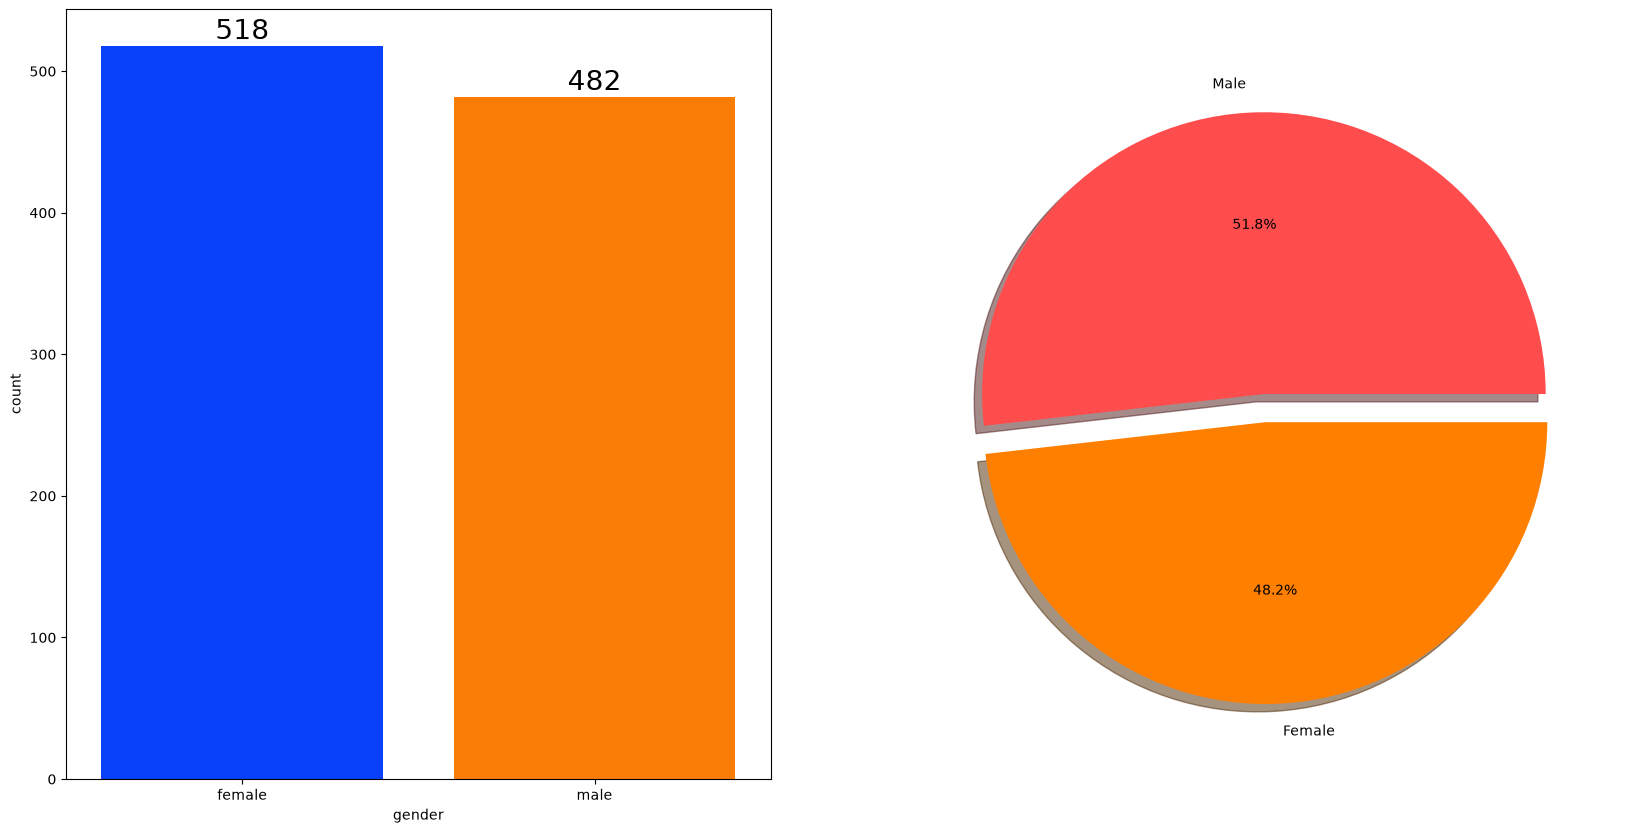

In [84]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['gender'],data=df,palette ='bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x=df['gender'].value_counts(),labels=['Male','Female'],explode=[0,0.1],autopct='%1.1f%%',shadow=True,colors=['#ff4d4d','#ff8000'])
plt.show()

#### Insights 
- Gender has balanced data with female students are 518 (48%) and male students are 482 (52%) 

#### BIVARIATE ANALYSIS ( Is gender has any impact on student's performance ? ) 

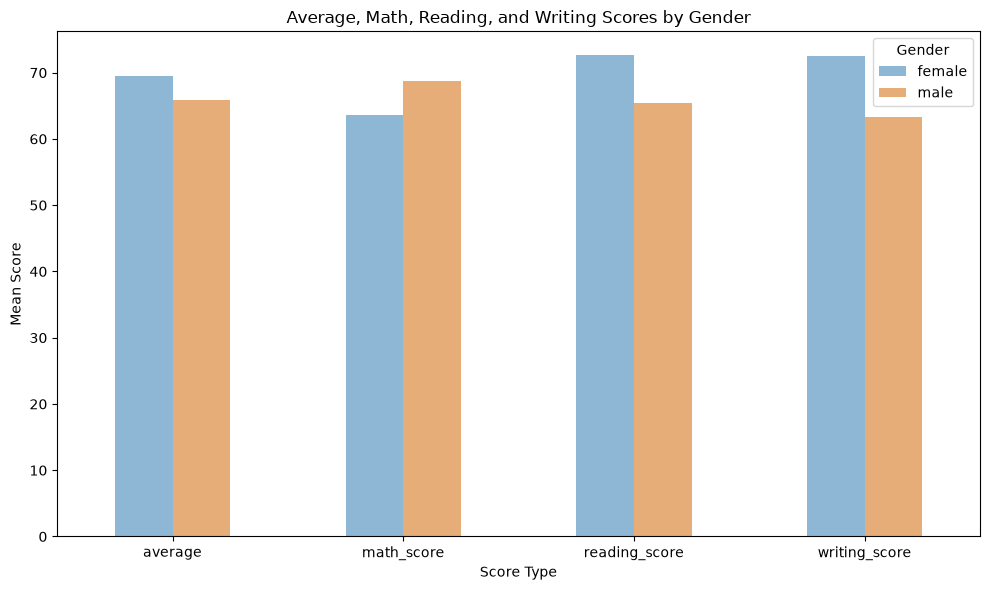

In [92]:
gender_group = (
    df.groupby("gender")[
        ["average", "math_score", "reading_score", "writing_score"]
    ]
    .mean()
    .reindex(["female", "male"])
)

gender_group.T.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#8DB7D5", "#E6AD78"]
)

plt.xlabel("Score Type")
plt.ylabel("Mean Score")
plt.title("Average, Math, Reading, and Writing Scores by Gender")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

#### Insights 
- On an average females have a better overall score than men.
- whereas males have scored higher in Maths.

####  RACE/EHNICITY COLUMN

#### UNIVARIATE ANALYSIS ( How is Group wise distribution ?)

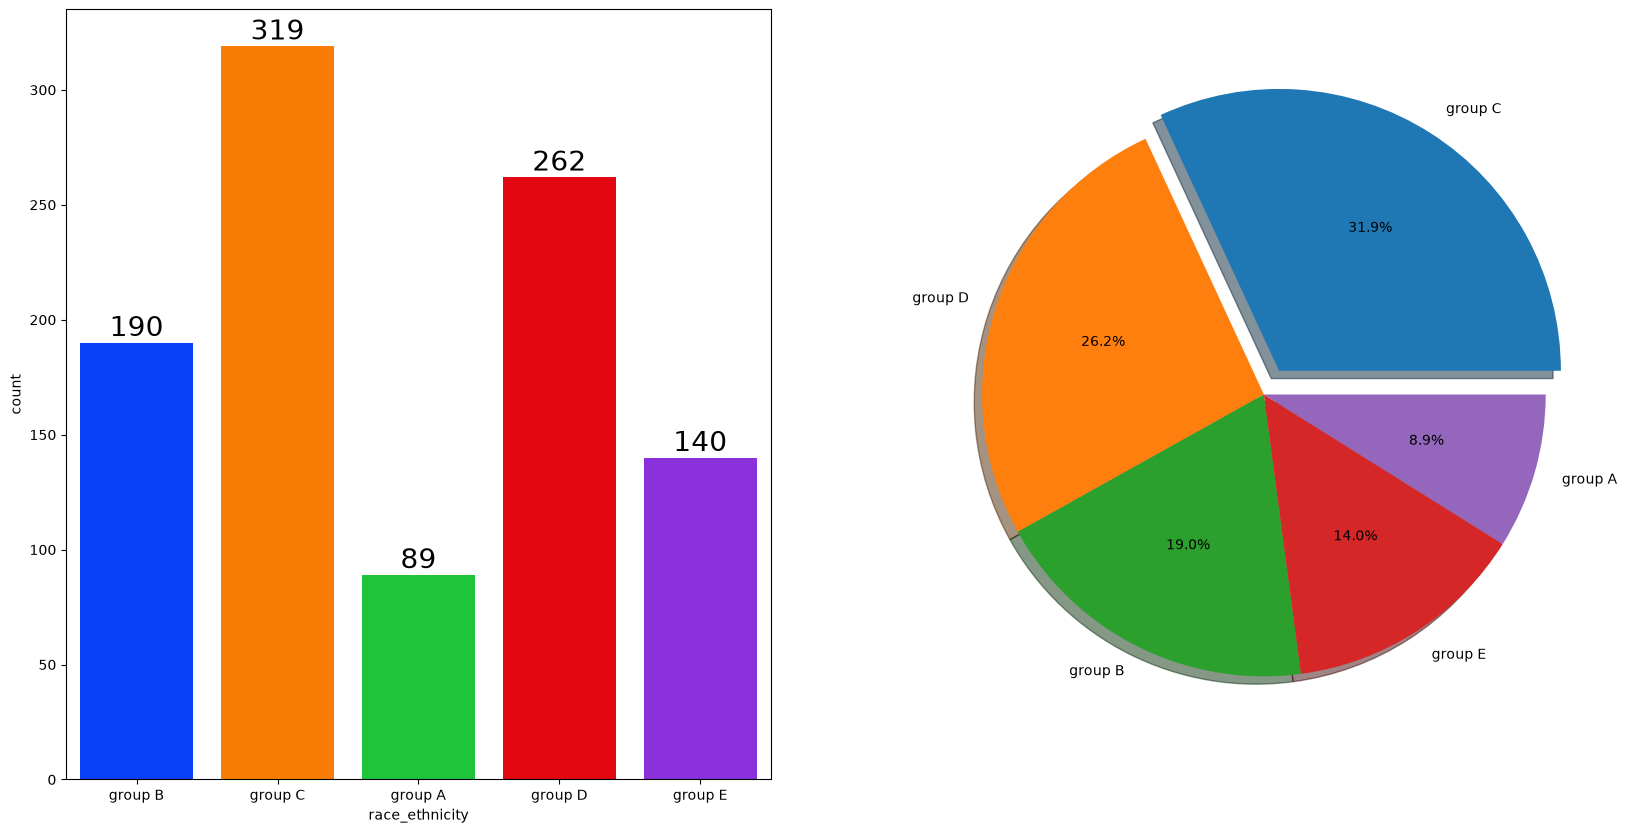

In [95]:
f,ax=plt.subplots(1,2,figsize=(20,10))
sns.countplot(x=df['race_ethnicity'],data=df,palette = 'bright',ax=ax[0],saturation=0.95)
for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=20)
    
plt.pie(x = df['race_ethnicity'].value_counts(),labels=df['race_ethnicity'].value_counts().index,explode=[0.1,0,0,0,0],autopct='%1.1f%%',shadow=True)
plt.show()   

#### Insights 
- Most of the student belonging from group C /group D.
- Lowest number of students belong to groupA.

#### BIVARIATE ANALYSIS ( Is Race/Ehnicity has any impact on student's performance ? )

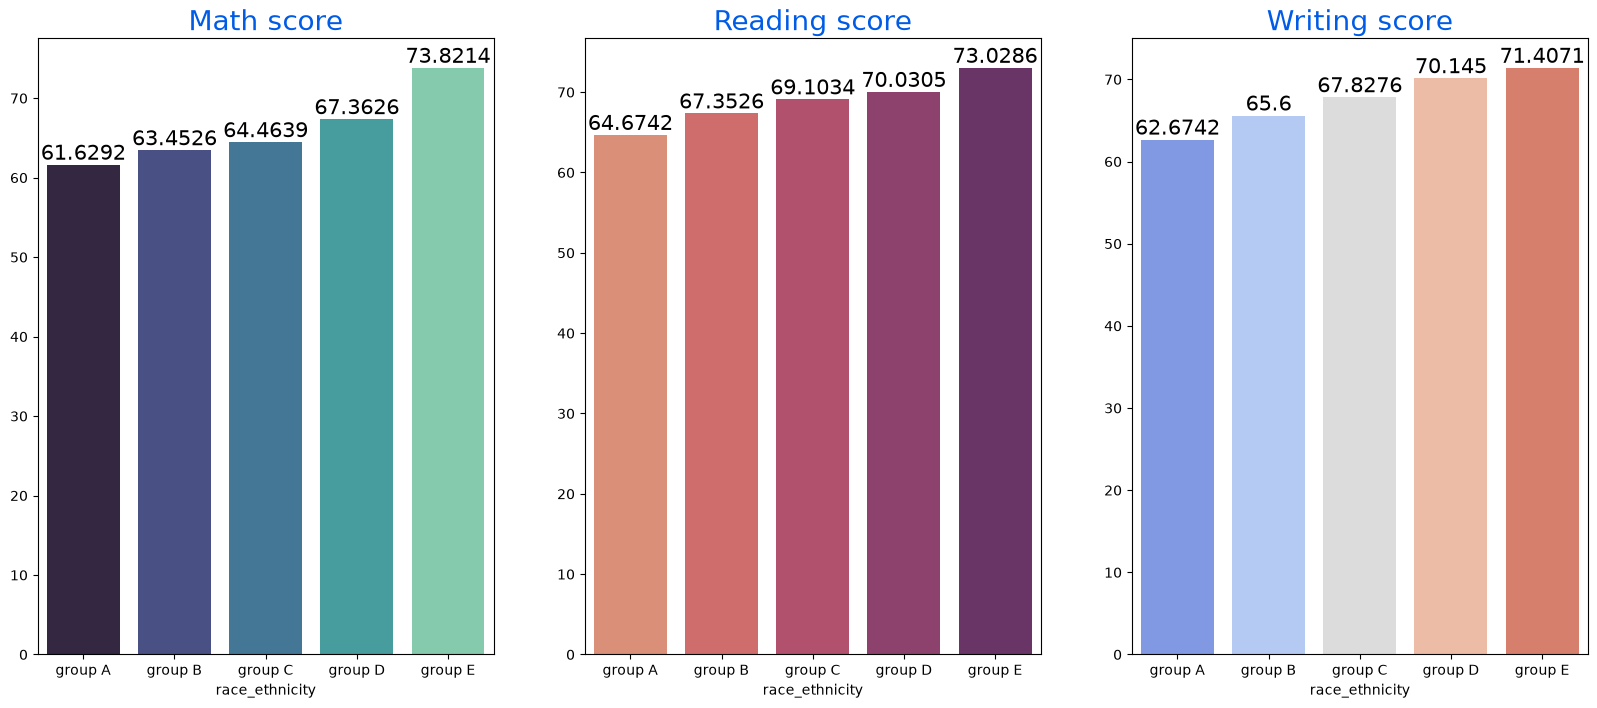

In [96]:
Group_data2=df.groupby('race_ethnicity')
f,ax=plt.subplots(1,3,figsize=(20,8))
sns.barplot(x=Group_data2['math_score'].mean().index,y=Group_data2['math_score'].mean().values,palette = 'mako',ax=ax[0])
ax[0].set_title('Math score',color='#005ce6',size=20)

for container in ax[0].containers:
    ax[0].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['reading_score'].mean().index,y=Group_data2['reading_score'].mean().values,palette = 'flare',ax=ax[1])
ax[1].set_title('Reading score',color='#005ce6',size=20)

for container in ax[1].containers:
    ax[1].bar_label(container,color='black',size=15)

sns.barplot(x=Group_data2['writing_score'].mean().index,y=Group_data2['writing_score'].mean().values,palette = 'coolwarm',ax=ax[2])
ax[2].set_title('Writing score',color='#005ce6',size=20)

for container in ax[2].containers:
    ax[2].bar_label(container,color='black',size=15)

#### Insights 
- Group E students have scored the highest marks. 
- Group A students have scored the lowest marks. 
- Students from a lower Socioeconomic status have a lower avg in all course subjects

####  PARENTAL LEVEL OF EDUCATION COLUMN

#### UNIVARIATE ANALYSIS ( What is educational background of student's parent ? )

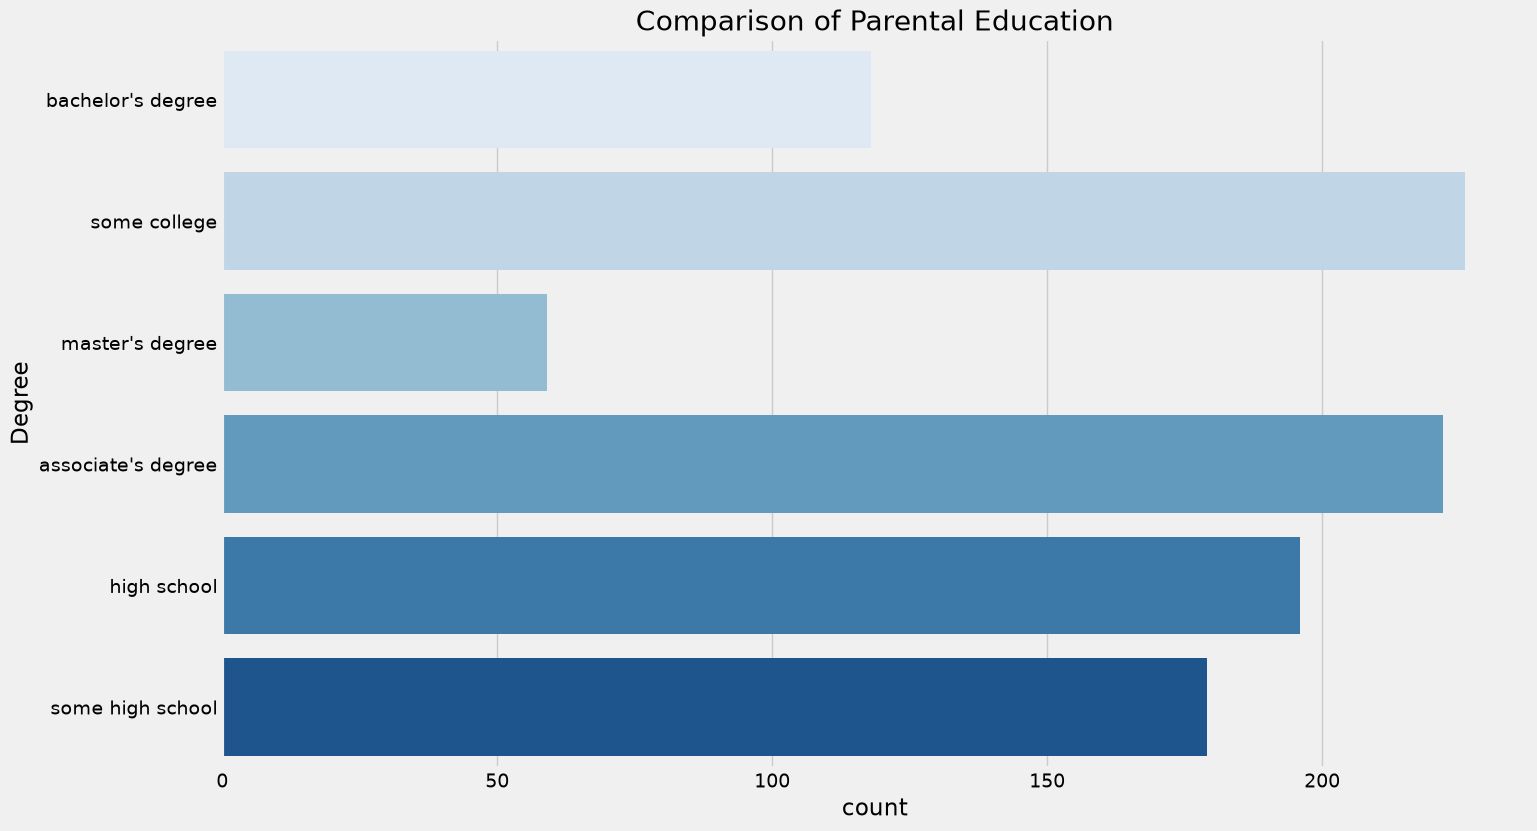

In [105]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('fivethirtyeight')
sns.countplot(df['parental_level_of_education'], palette = 'Blues')
plt.title('Comparison of Parental Education', fontweight = 30, fontsize = 20)
plt.xlabel('count')
plt.ylabel('Degree')
plt.show()

#### Insights 
- Largest number of parents are from some college.

#### BIVARIATE ANALYSIS ( Is parental education has any impact on student's performance ? )

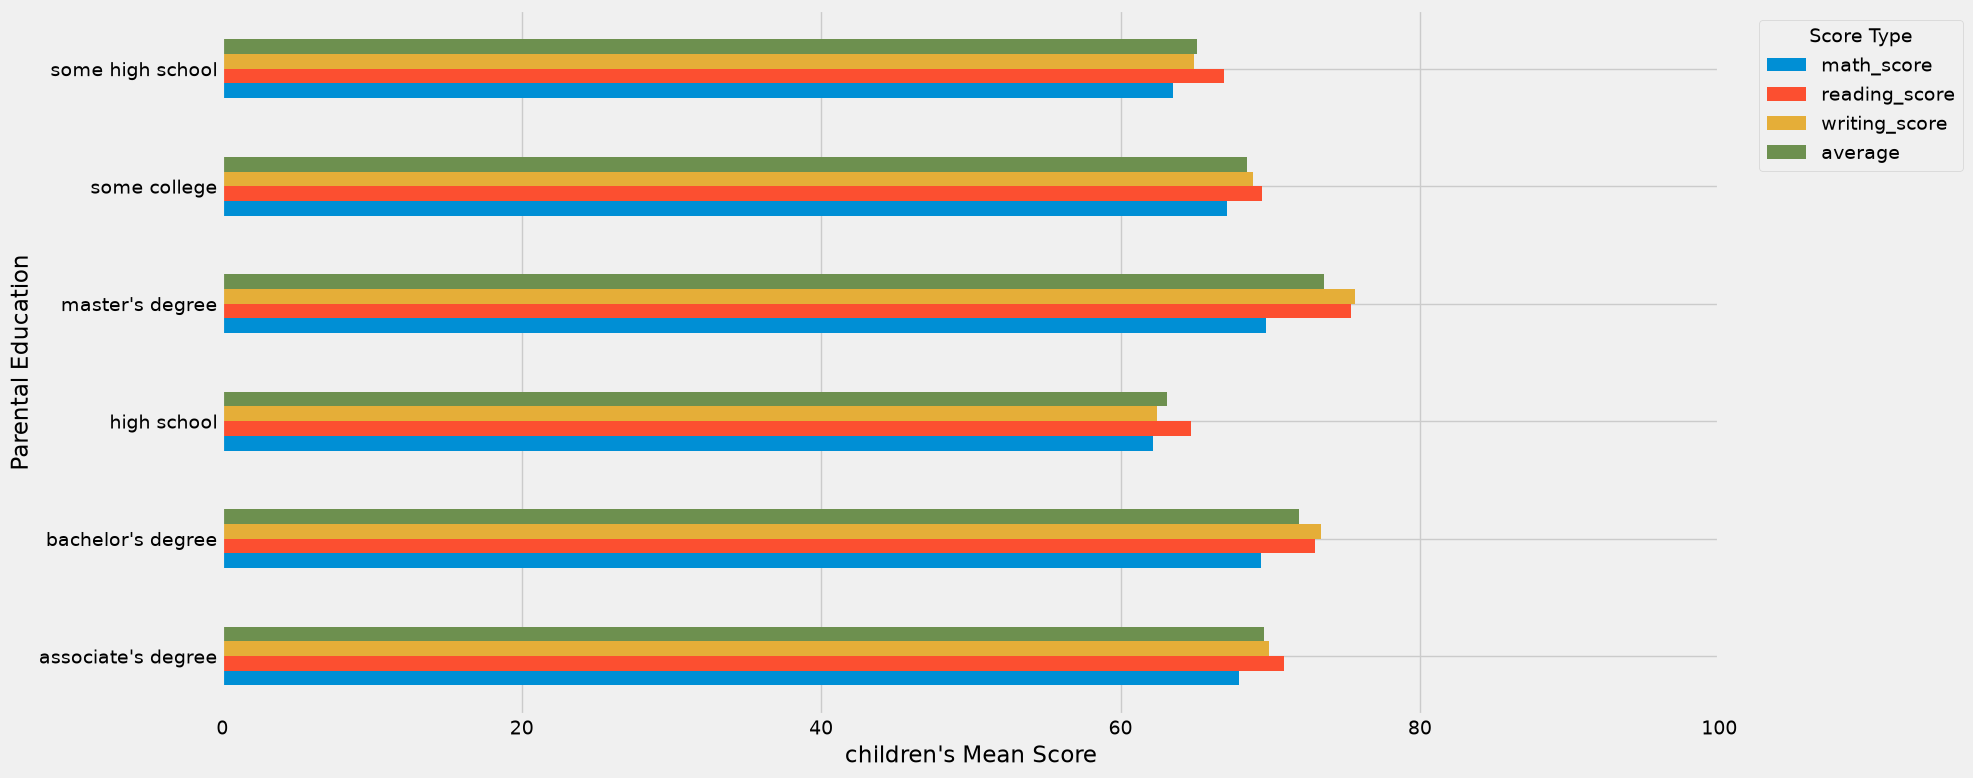

In [120]:
scores = ["math_score", "reading_score", "writing_score", "average"]

df.groupby("parental_level_of_education")[scores].mean().plot(
    kind="barh",
    figsize=(20, 8)
)

plt.xlabel("children's Mean Score")
plt.ylabel("Parental Education")
plt.legend(title="Score Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xlim(0,100)
plt.tight_layout()
plt.show()

#### Insights 
- The score of student whose parents possess master and bachelor level education are higher than others.


####  LUNCH COLUMN 

#### UNIVARIATE ANALYSIS ( Which type of lunch is most common amoung students ? )

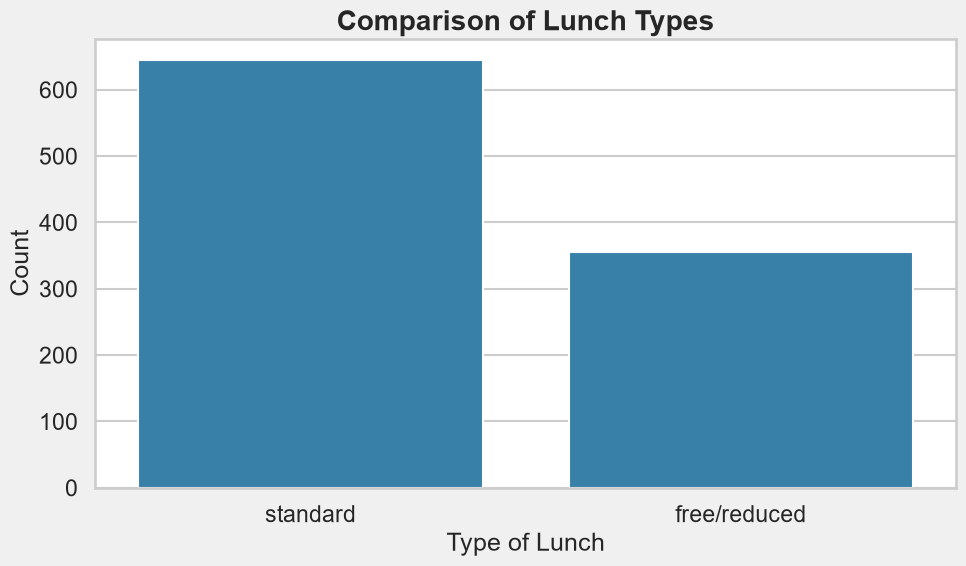

In [122]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", context="talk")

sns.countplot(
    data=df,
    x="lunch",
    color=sns.color_palette("PuBu", 5)[3]
)

plt.title("Comparison of Lunch Types", fontweight="bold", fontsize=20)
plt.xlabel("Type of Lunch")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

#### Insights 
- Students being served Standard lunch was more than free/reduced lunch

#### BIVARIATE ANALYSIS (  Is lunch type intake has any impact on student's performance ? )

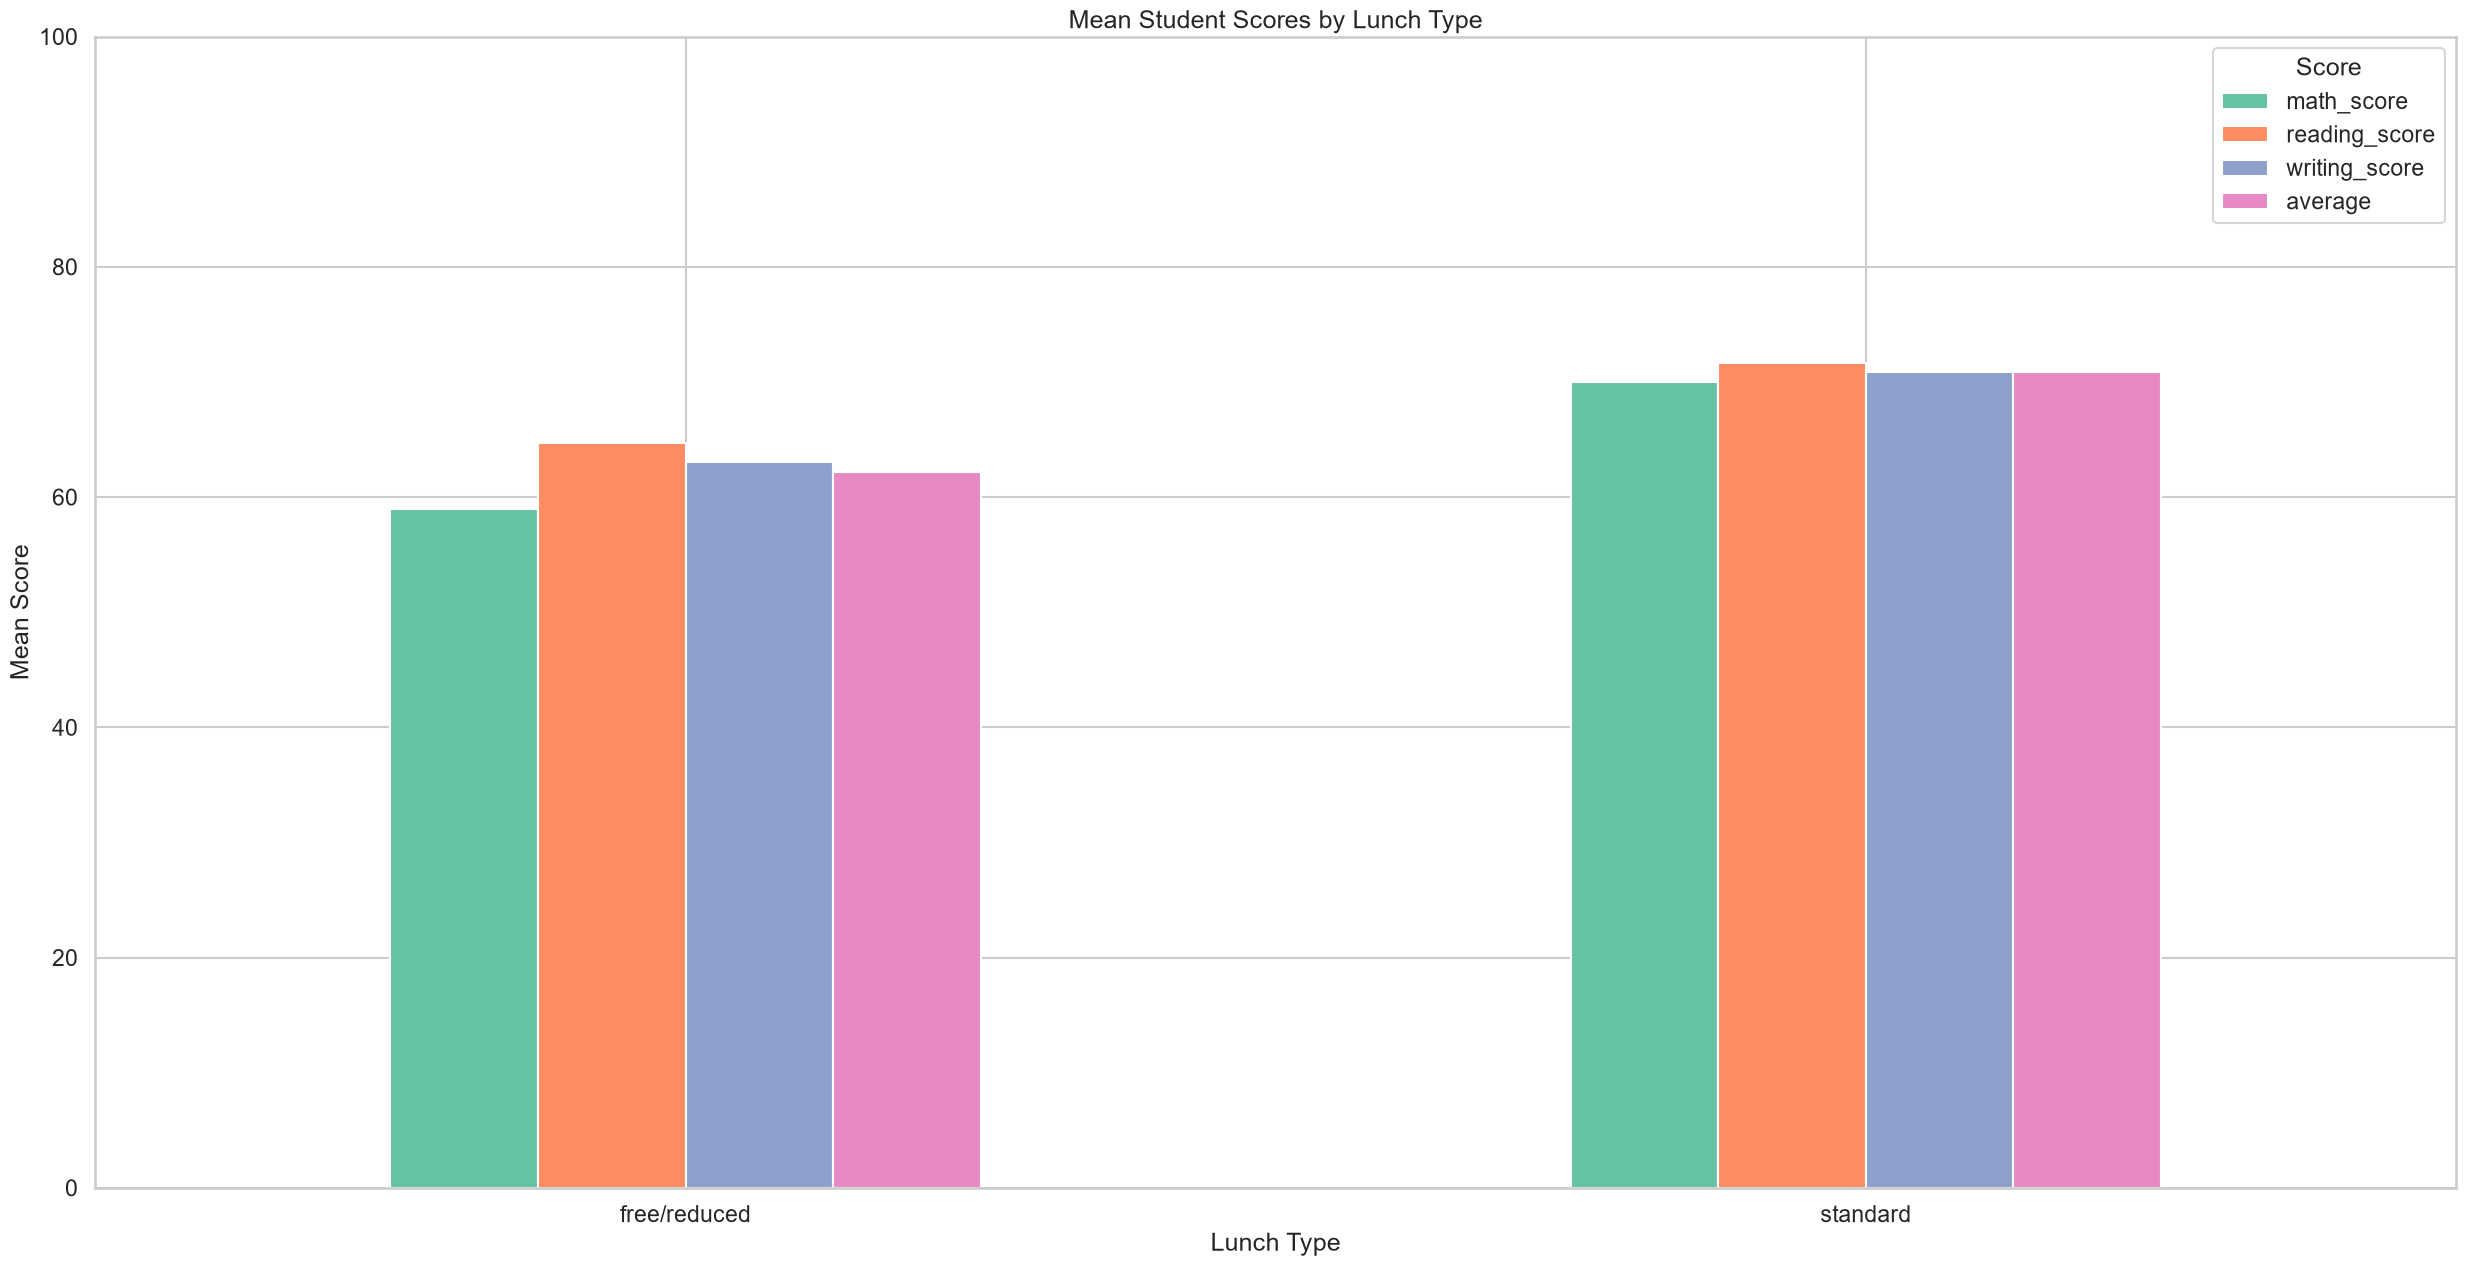

In [132]:
score_columns = ["math_score", "reading_score", "writing_score", "average"]

lunch_means = df.groupby("lunch")[score_columns].mean()

ax = lunch_means.plot(
    kind="bar",
    figsize=(25, 13),
    color=sns.color_palette("Set2", n_colors=len(score_columns))
)

ax.set_title("Mean Student Scores by Lunch Type")
ax.set_xlabel("Lunch Type")
ax.set_ylabel("Mean Score")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Score", loc="upper right")
plt.tight_layout()
plt.show()

#### Insights 
- Students who get Standard Lunch tend to perform better than students who got free/reduced lunch


####  TEST PREPARATION COURSE COLUMN 

#### BIVARIATE ANALYSIS ( Is Test prepration course has any impact on student's performance ? )

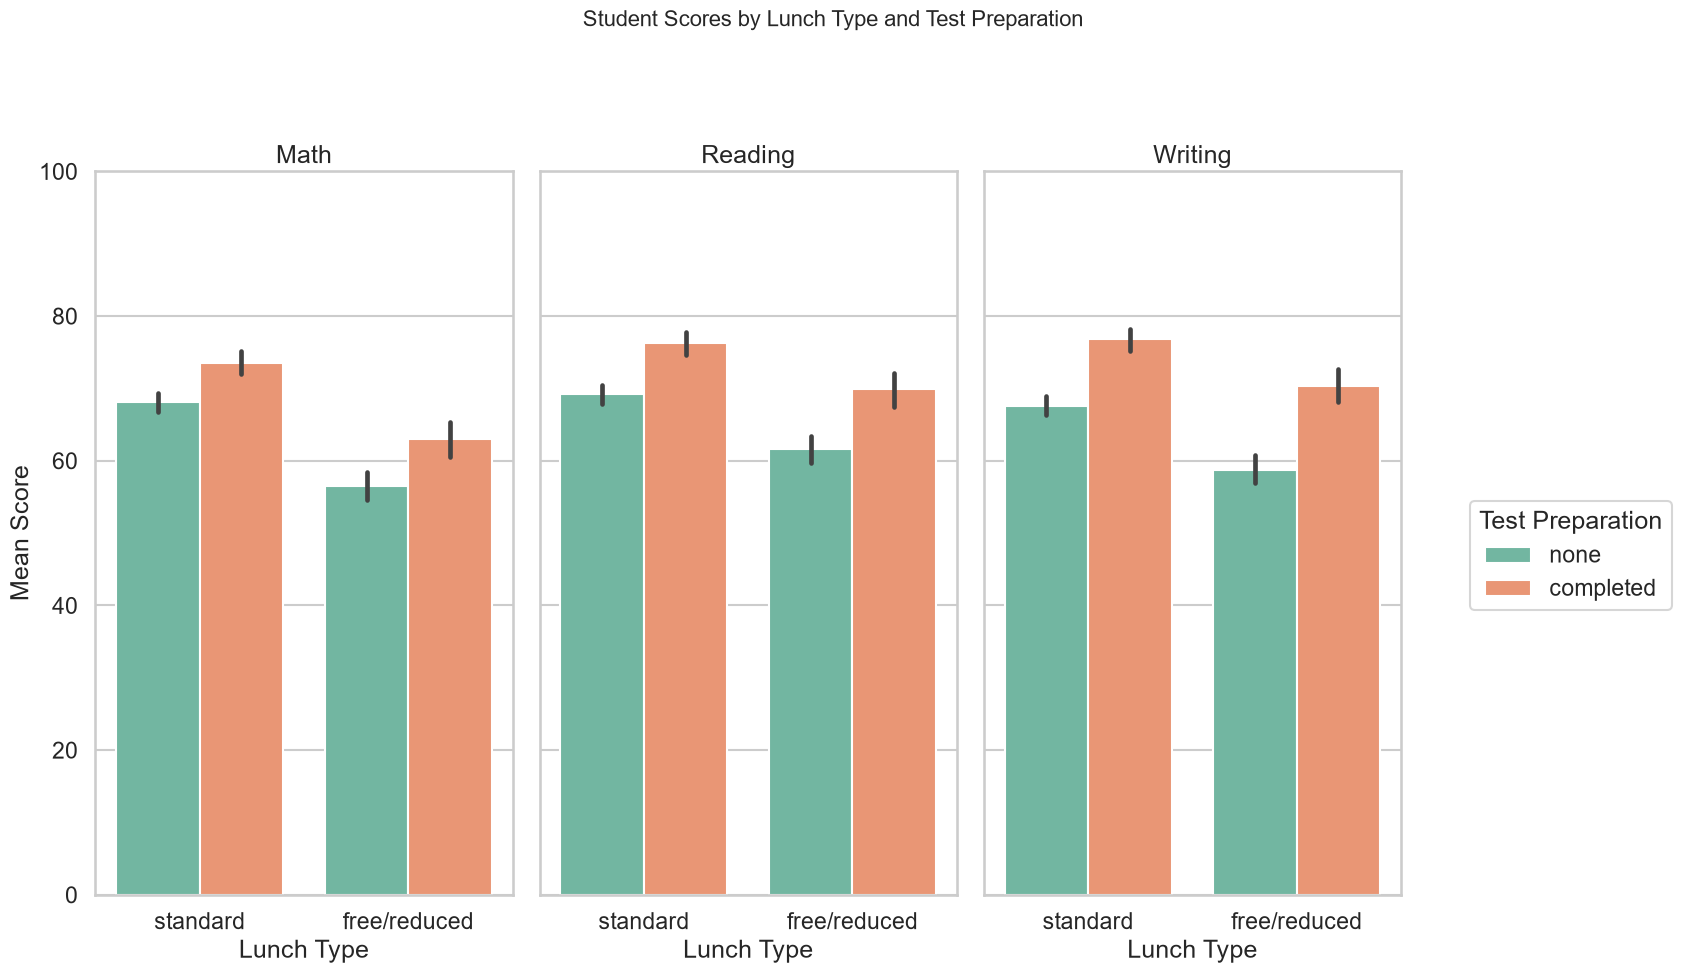

In [140]:
fig, axes = plt.subplots(1, 3, figsize=(17, 10), sharey=True)

scores = ["math_score", "reading_score", "writing_score"]
titles = ["Math", "Reading", "Writing"]

for ax, score, title in zip(axes, scores, titles):
    sns.barplot(
        data=df,
        x="lunch",
        y=score,
        hue="test_preparation_course",
        palette="Set2",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Lunch Type")
    ax.set_ylim(0, 100)

    if ax is axes[0]:
        handles, labels = ax.get_legend_handles_labels()

    ax.legend_.remove()

axes[0].set_ylabel("Mean Score")
axes[1].set_ylabel("")
axes[2].set_ylabel("")

fig.suptitle("Student Scores by Lunch Type and Test Preparation", fontsize=16)
fig.legend(
    handles,
    labels,
    title="Test Preparation",
    loc="upper right",
    bbox_to_anchor=(1, 0.5)
)

fig.tight_layout(rect=[0, 0, 0.85, 0.92])
plt.show()

#### Insights  
- Students who have completed the Test Prepration Course have scores higher in all three categories than those who haven't taken the course

####  CHECKING OUTLIERS

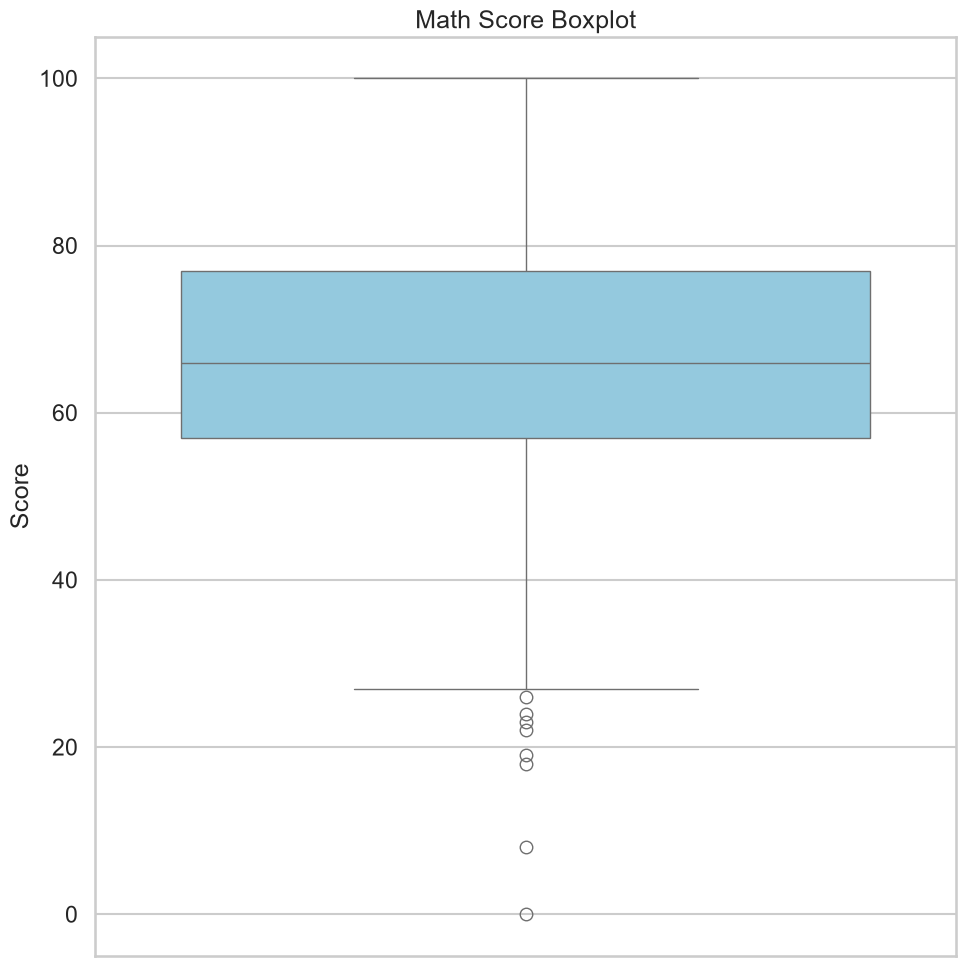

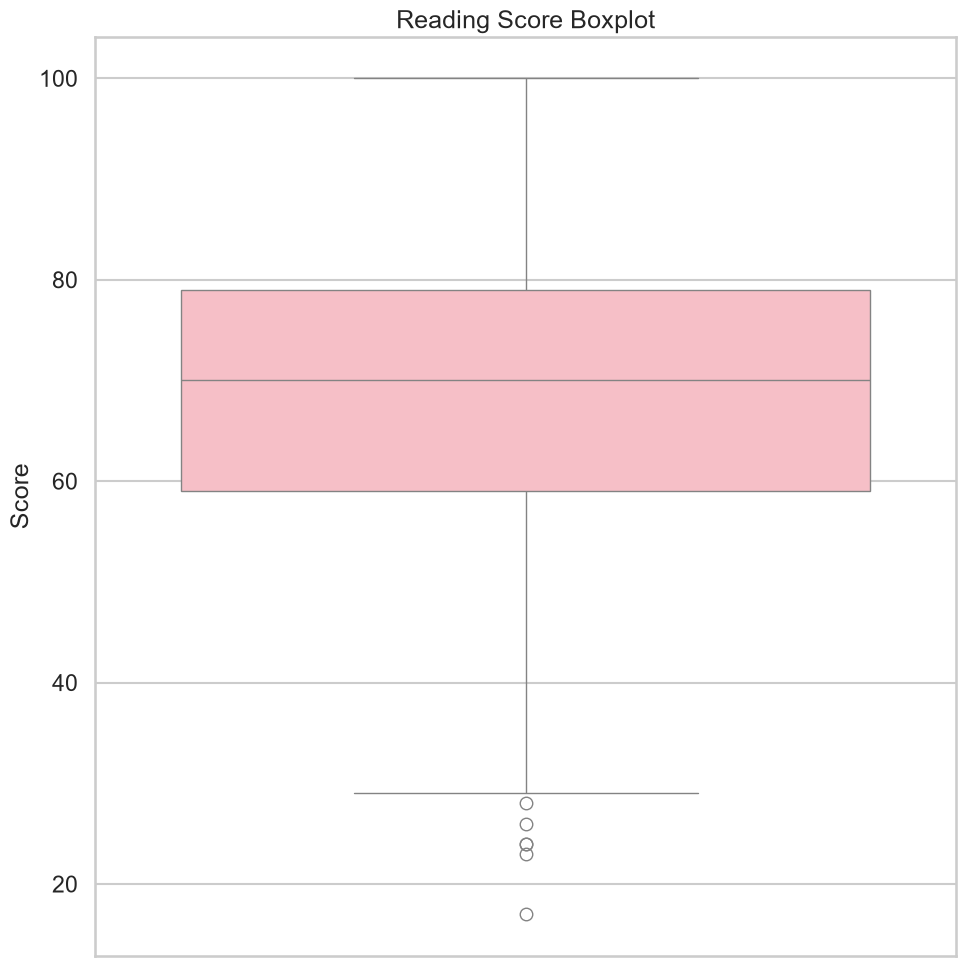

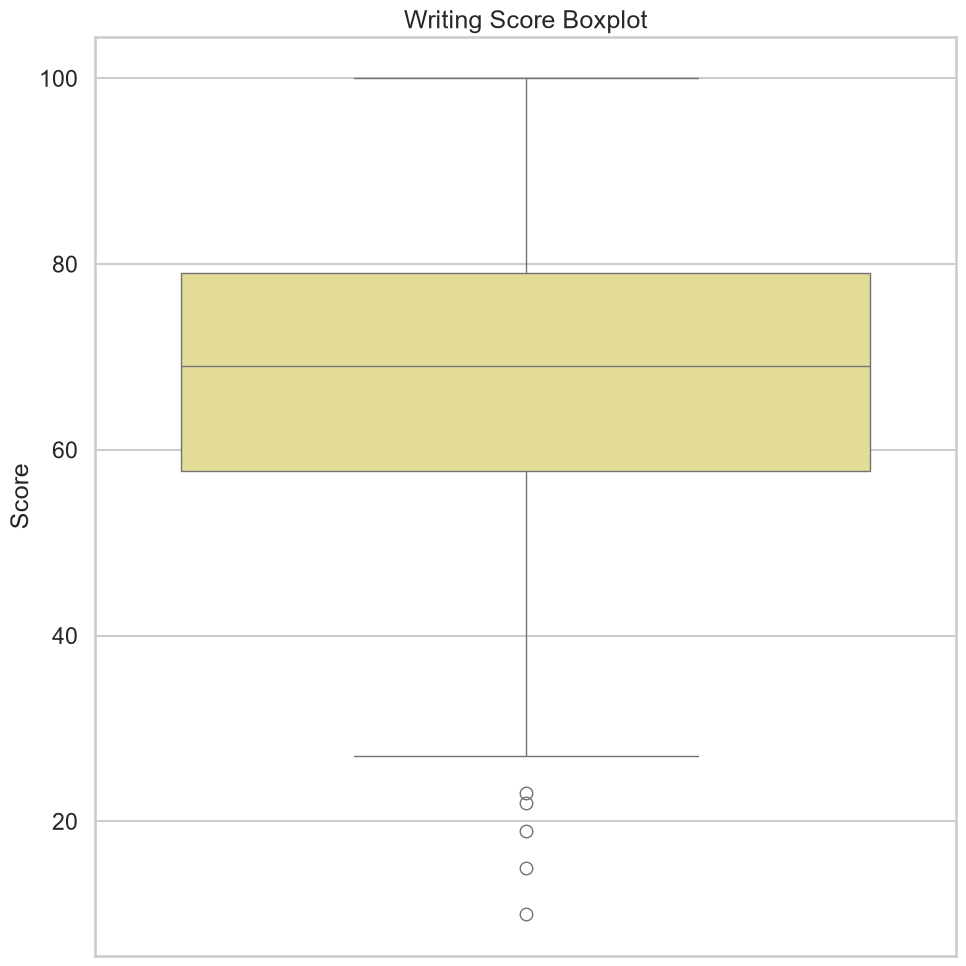

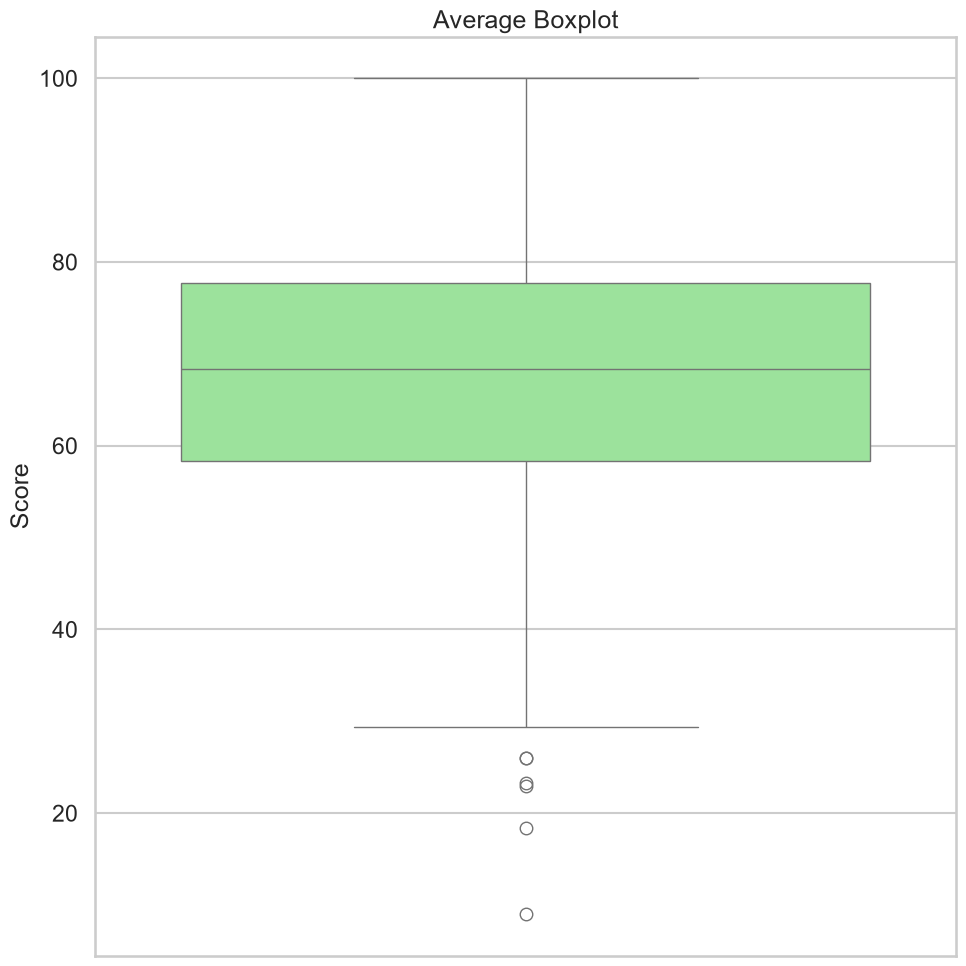

In [145]:
scores = ["math_score", "reading_score", "writing_score", "average"]
colors = ["skyblue", "lightpink", "khaki", "lightgreen"]

for score, color in zip(scores, colors):
    plt.figure(figsize=(10, 10))
    sns.boxplot(y=df[score], color=color)
    plt.title(f"{score.replace('_', ' ').title()} Boxplot")
    plt.ylabel("Score")
    plt.tight_layout()
    plt.show()

####  MUTIVARIATE ANALYSIS USING PAIRPLOT

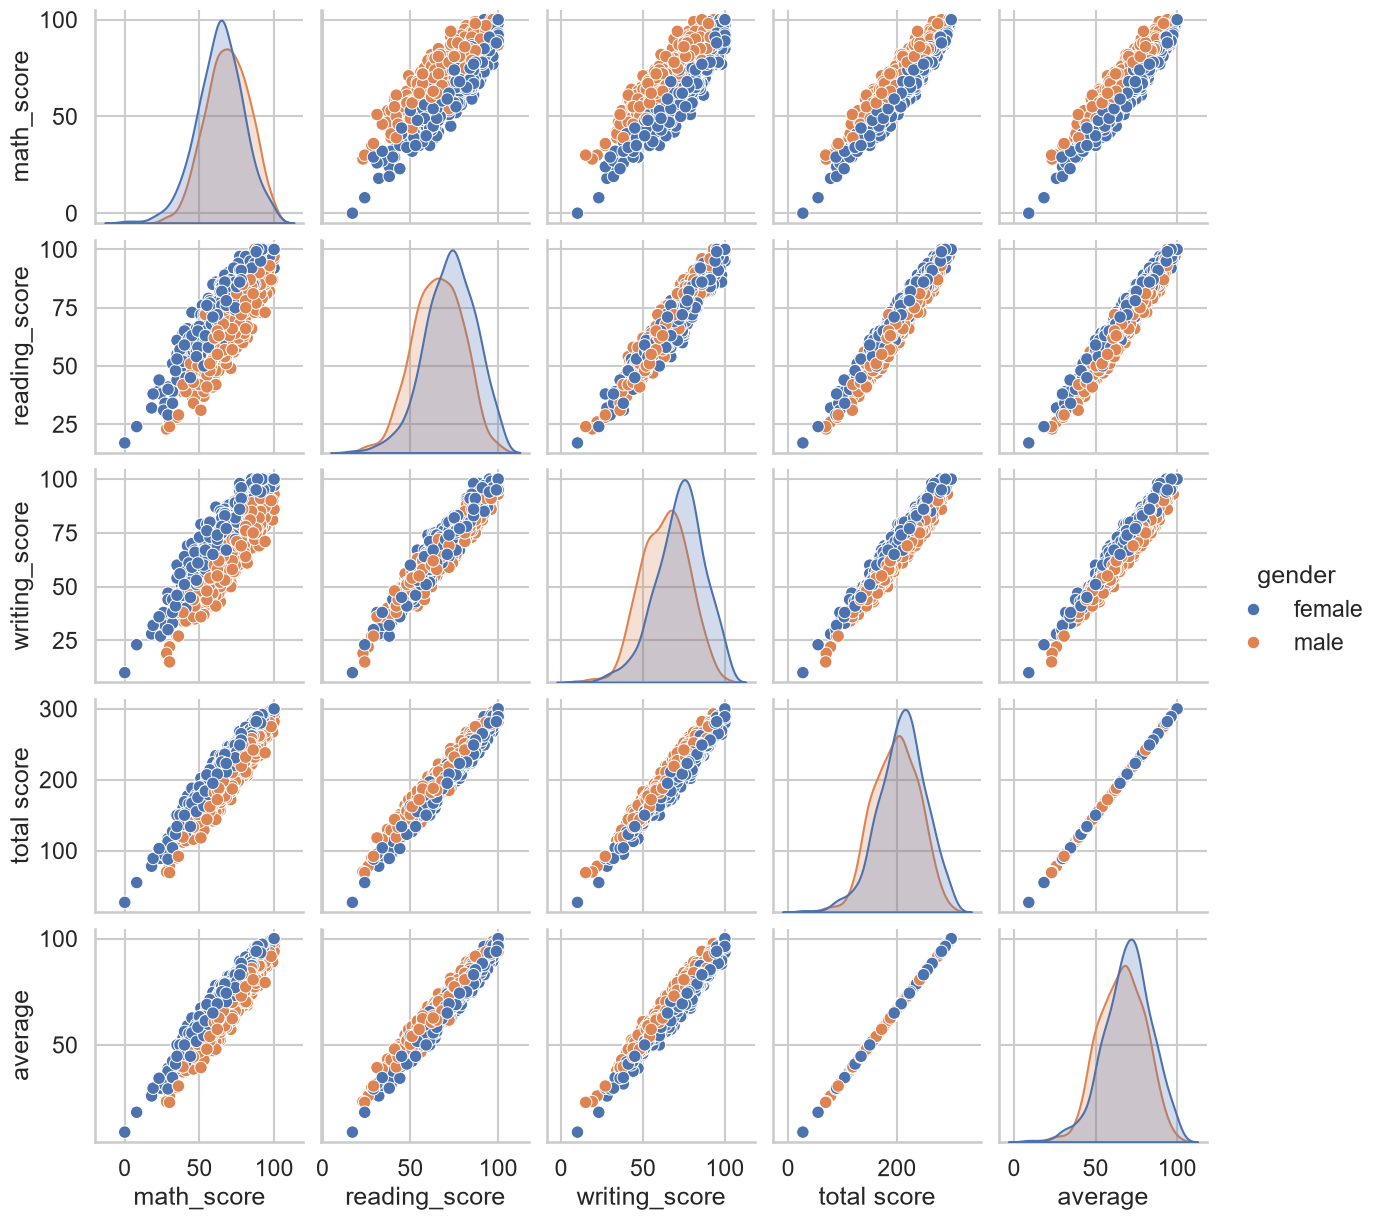

In [146]:
sns.pairplot(df,hue = 'gender')
plt.show()

#### Insights
- From the above plot it is clear that all the scores increase linearly with each other.

###  Conclusions
- Student's Performance is related with lunch, race, parental level education
- Females lead in pass percentage and also are top-scorers
- Student's Performance is not much related with test preparation course
- Finishing preparation course is benefitial.